# **Supervised Learning**
## Banana Quality Classification with $k$-Nearest Neighbors ($k$-NN) and Random Forest

## **Introduction**

In this notebook we use two supervised learning algorithms, **$k$-Nearest Neighbors ($k$-NN)** and **Random Forest**, to classify **banana tiers** (bunches of bananas, also called *hands*) into four **commercial quality classes** using their **color** and **size**.

**The idea in one sentence:** we measure the color and the finger length of a banana tier, and the model guesses its quality class.

**Dataset.** *Tier-based Dataset: Musa-Acuminata Banana Fruit Species* (Piedad et al., 2018), published on Mendeley Data (DOI: [10.17632/zk3tkxndjw.2](https://doi.org/10.17632/zk3tkxndjw.2)). The bananas come from a plantation in the Philippines and were classified by a local expert of the Department of Agriculture into four classes. Each tier was photographed from six sides (front, back, left, right, top and bottom), and for every photo the average **R**ed, **G**reen and **B**lue color values were extracted. The length of the top middle finger was measured by hand in millimeters.

| Column | Meaning |
|---|---|
| `SampleID` | Identifier of the banana tier (194 tiers in total) |
| `R`, `G`, `B` | Average red, green and blue values of the photo (0-255) |
| `view` | Side from which the photo was taken |
| `class` | Quality class (target): 1 = extra class, 4 = reject; 2 and 3 are the intermediate grades |
| `size` | Length of the top middle finger in millimeters |


The notebook covers: loading the data, exploratory data analysis, preprocessing, visualization, a $k$-NN model, finding the best value of $k$, a Random Forest model, a prediction for a new banana, and conclusions.

## **Contents**

### Loading the banana dataset

In [2]:
# Import the libraries we need
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid") # Set the visual style of all plots

The file `banana_features.csv` is stored **locally**, in the same folder as this notebook.

In [3]:
# Load the local CSV file
bananas = pd.read_csv('banana_features.csv')

### Exploratory Data Analysis

In [4]:
# First 5 rows
bananas.head()

,SampleID,R,G,B,view,class,size
0,1,128.387045,148.385068,88.125925,front,3,178
1,2,91.396778,114.322955,48.277243,front,4,147
2,3,87.804595,112.774147,50.034383,front,1,154
3,4,81.901377,103.886640,37.110752,front,1,160
4,5,94.311041,120.103604,56.237598,front,1,162


In [4]:
# Last 5 rows
bananas.tail()

,SampleID,R,G,B,view,class,size
1159,190,113.887423,128.594981,79.059493,bottom,4,92
1160,191,101.237979,120.566841,66.788490,bottom,4,97
1161,192,96.327428,106.997443,57.930494,bottom,4,87
1162,193,110.464601,122.383294,53.521085,bottom,4,105
1163,194,129.667650,134.628473,56.677653,bottom,4,97


In [5]:
# Structure of the dataset: columns, types and missing values
bananas.info()

<class 'pandas.DataFrame'>
RangeIndex: 1164 entries, 0 to 1163
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   SampleID  1164 non-null   int64  
 1   R         1164 non-null   float64
 2   G         1164 non-null   float64
 3   B         1164 non-null   float64
 4   view      1164 non-null   str    
 5   class     1164 non-null   int64  
 6   size      1164 non-null   int64  
dtypes: float64(3), int64(3), str(1)
memory usage: 63.8 KB


In [7]:
# Are there missing values?
bananas.isna().sum()

SampleID    0
R           0
G           0
B           0
view        0
class       0
size        0
dtype: int64

There are **1,164 rows** and **no missing values**. But 1,164 is *not* the number of bananas: each banana tier was photographed from 6 sides, so every `SampleID` appears 6 times. Let's check that.

In [5]:
# Each view should appear once per tier: 194 tiers x 6 views = 1,164 rows
print(bananas['view'].value_counts())
print("\nNumber of different banana tiers:", bananas['SampleID'].nunique())

view
front     194
left      194
right     194
back      194
top       194
bottom    194
Name: count, dtype: int64

Number of different banana tiers: 194


### Data preprocessing

**Why we cannot use the 1,164 rows directly.** If we split the rows randomly into training and test sets, the 6 photos of the same banana tier would end up in *both* sets. The model would then be tested on a banana it has already seen (from another side), and the accuracy would look better than it really is. This problem is called **data leakage**.

**Solution:** we group the rows by `SampleID` and take the **mean** of R, G and B over the 6 views. The class and the size are the same in all 6 photos, so we just keep them. The result is **one row per banana tier** (194 rows).

We also drop the columns `SampleID` and `view` (it disappears after averaging).

In [6]:
# One row per banana tier: mean color over the 6 views, same size and class
df = (bananas.groupby('SampleID')
              .agg(R=('R', 'mean'), G=('G', 'mean'), B=('B', 'mean'),
                   size=('size', 'first'), quality=('class', 'first'))
              .reset_index(drop=True))

df.head(6)

,R,G,B,size,quality
0,105.927305,125.944252,64.087052,178,3
1,69.971837,88.845921,34.628647,147,4
2,77.543110,101.503586,38.604124,154,1
3,91.399827,112.026587,48.031922,160,1
4,78.367356,104.769758,41.318993,162,1
5,87.261362,107.946519,45.141503,149,1


### Data visualization

#### How many banana tiers are there in each class?

In [22]:
# New shape and number of tiers per class
print("Shape:", df.shape)
print(df['quality'].value_counts().sort_index())

Shape: (194, 5)
quality
1    65
2    49
3    30
4    50
Name: count, dtype: int64


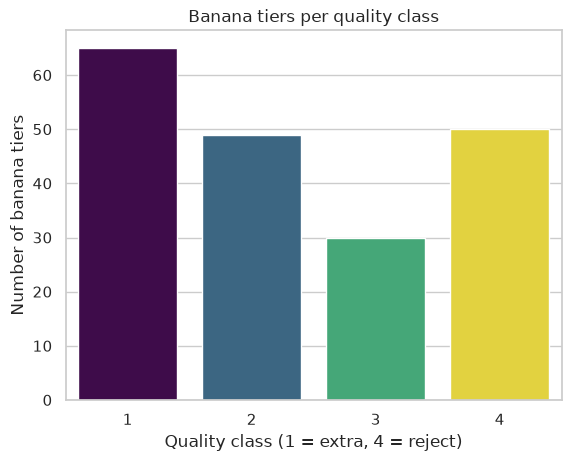

In [23]:
sns.countplot(x='quality', hue='quality', data=df, palette='viridis', legend=False)
plt.xlabel('Quality class (1 = extra, 4 = reject)')
plt.ylabel('Number of banana tiers')
plt.title('Banana tiers per quality class')
plt.show()

#### Does the size change with the class?

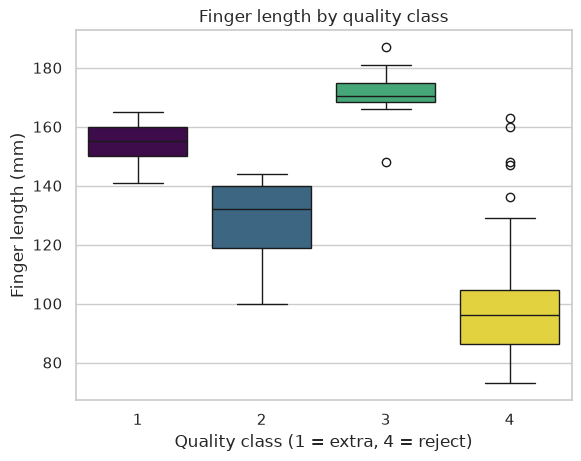

In [24]:
sns.boxplot(x='quality', y='size', hue='quality', data=df, palette='viridis', legend=False)
plt.xlabel('Quality class (1 = extra, 4 = reject)')
plt.ylabel('Finger length (mm)')
plt.title('Finger length by quality class')
plt.show()

#### Does the color change with the class?

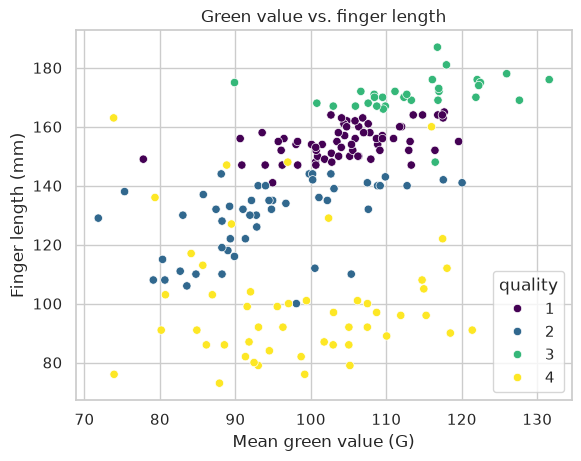

In [25]:
sns.scatterplot(x='G', y='size', hue='quality', palette='viridis', data=df)
plt.xlabel('Mean green value (G)')
plt.ylabel('Finger length (mm)')
plt.title('Green value vs. finger length')
plt.show()

#### Relationship between all the variables

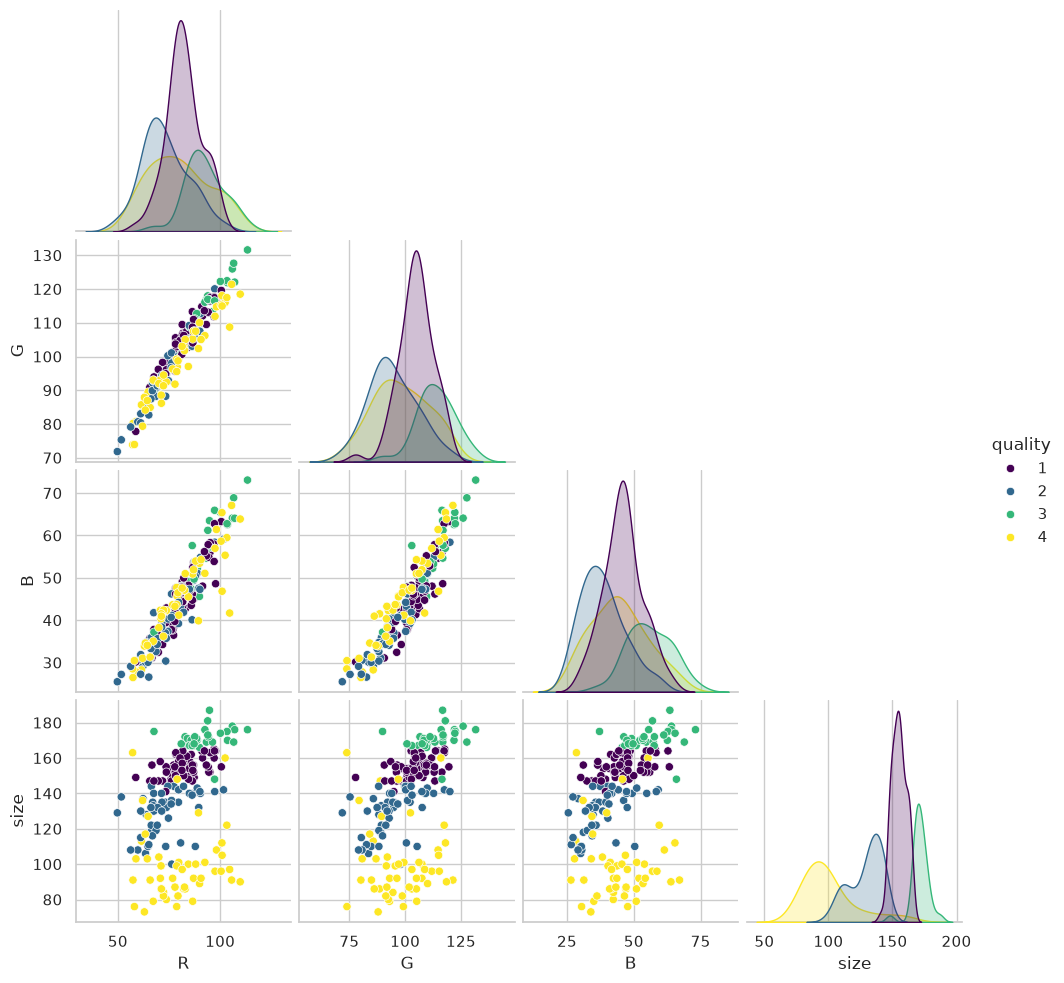

In [26]:
sns.pairplot(df, hue='quality', palette='viridis', corner=True)
plt.show()

### Modeling with $k$-NN

#### Isolate the predictor variables

In [27]:
# Predictor variables (features)
X = df[['R', 'G', 'B', 'size']]
X.head()

,R,G,B,size
0,105.927305,125.944252,64.087052,178
1,69.971837,88.845921,34.628647,147
2,77.543110,101.503586,38.604124,154
3,91.399827,112.026587,48.031922,160
4,78.367356,104.769758,41.318993,162


#### Isolate the target variable

In [28]:
# Target variable: the quality class
y = df['quality']
y.head()

0    3
1    4
2    1
3    1
4    1
Name: quality, dtype: int64

#### Split the data into training and test sets

We keep 80% of the tiers for training and 20% for testing. Two details:
- `stratify=y` keeps the same proportion of each class in both sets (important because the classes are not perfectly balanced).
- `random_state=42` makes the split reproducible: everyone who runs the notebook gets the same result.

In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print("Training tiers:", len(X_train), "| Test tiers:", len(X_test))

Training tiers: 155 | Test tiers: 39


In [30]:
from sklearn.preprocessing import StandardScaler
#  converts every variable to the same scale (z-score)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # learn the scale from the training data
X_test_scaled = scaler.transform(X_test)         # apply the same scale to the test data

#### Train the $k$-NN classifier

We start with $k = 5$ neighbors: to classify a new banana, the model looks at the 5 most similar bananas in the training data and picks the most common class among them.

In [32]:
from sklearn.neighbors import KNeighborsClassifier

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](4,)","[1,2,3,4]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [33]:
# Predictions on the test set
y_pred = knn.predict(X_test_scaled)
y_pred

array([3, 1, 1, 2, 4, 2, 1, 4, 1, 1, 4, 2, 4, 4, 2, 1, 1, 4, 4, 1, 2, 4,
       1, 1, 1, 1, 1, 3, 2, 1, 1, 2, 1, 2, 2, 4, 3, 1, 4])

### Model evaluation

**Accuracy** is the number of correct predictions divided by the total number of predictions:

$\text{Accuracy} = \frac{\text{Number of correct predictions}}{\text{Total number of predictions}}$

In [34]:
from sklearn.metrics import accuracy_score

acc_knn5 = accuracy_score(y_test, y_pred)
print("k-NN (k=5) accuracy:", round(acc_knn5, 3))

k-NN (k=5) accuracy: 0.744


#### Classification report

- **Precision:** of the tiers the model labeled as a class, how many really belong to it?
- **Recall:** of the tiers that really belong to a class, how many did the model find?
- **F1-score:** the harmonic mean of precision and recall.
- **Support:** number of test tiers of each class.

In [35]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           1       0.71      0.92      0.80        13
           2       0.67      0.60      0.63        10
           3       1.00      0.50      0.67         6
           4       0.80      0.80      0.80        10

    accuracy                           0.74        39
   macro avg       0.79      0.71      0.72        39
weighted avg       0.77      0.74      0.74        39



#### Confusion matrix

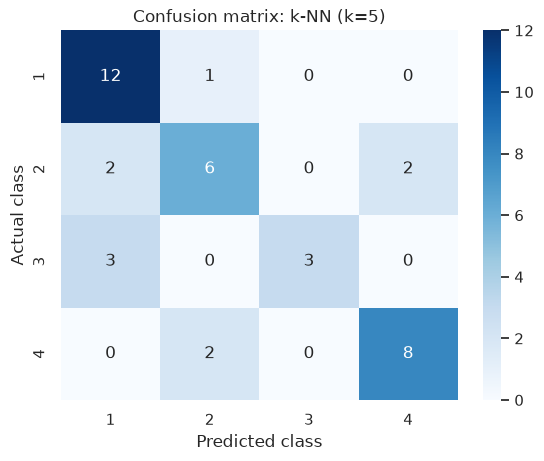

In [36]:
from sklearn.metrics import confusion_matrix

labels = sorted(y.unique())
cf_matrix = confusion_matrix(y_test, y_pred, labels=labels)

sns.heatmap(cf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted class')
plt.ylabel('Actual class')
plt.title('Confusion matrix: k-NN (k=5)')
plt.show()

### Finding the optimal value of $k$

In [ ]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
k_values = range(1, 26)
cv_scores = []

for k in k_values:
    # The pipeline scales the data inside each fold, so there is no leakage
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='accuracy')
    cv_scores.append(scores.mean())


best_score = max(cv_scores)
tied = [k for k, sc in zip(k_values, cv_scores) if sc >= best_score - 0.01]
best_k = max(tied)

print("Highest cross-validated accuracy:", round(best_score, 3),
      "(k =", list(k_values)[int(np.argmax(cv_scores))], ")")
print("Values of k practically tied with the best:", tied)
print("Chosen k:", best_k, "| cross-validated accuracy:", round(cv_scores[best_k - 1], 3))

Highest cross-validated accuracy: 0.785 (k = 1 )
Values of k practically tied with the best: [1, 3]
Chosen k: 3 | cross-validated accuracy: 0.778


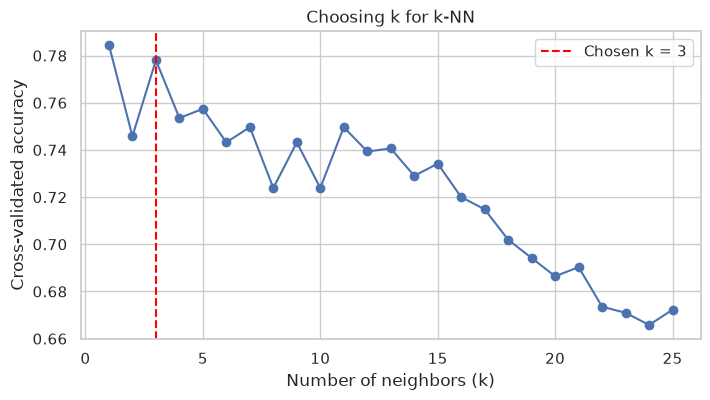

In [28]:
plt.figure(figsize=(8, 4))
plt.plot(list(k_values), cv_scores, marker='o')
plt.axvline(best_k, color='red', linestyle='--', label=f'Chosen k = {best_k}')
plt.xlabel('Number of neighbors (k)')
plt.ylabel('Cross-validated accuracy')
plt.title('Choosing k for k-NN')
plt.legend()
plt.show()

In [29]:
knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train_scaled, y_train)
y_pred_best = knn_best.predict(X_test_scaled)

acc_knn_best = accuracy_score(y_test, y_pred_best)
print(f"k-NN (k={best_k}) test accuracy:", round(acc_knn_best, 3))
print()
print(classification_report(y_test, y_pred_best))

k-NN (k=3) test accuracy: 0.769

              precision    recall  f1-score   support

           1       0.72      1.00      0.84        13
           2       0.75      0.60      0.67        10
           3       1.00      0.50      0.67         6
           4       0.80      0.80      0.80        10

    accuracy                           0.77        39
   macro avg       0.82      0.73      0.74        39
weighted avg       0.79      0.77      0.76        39



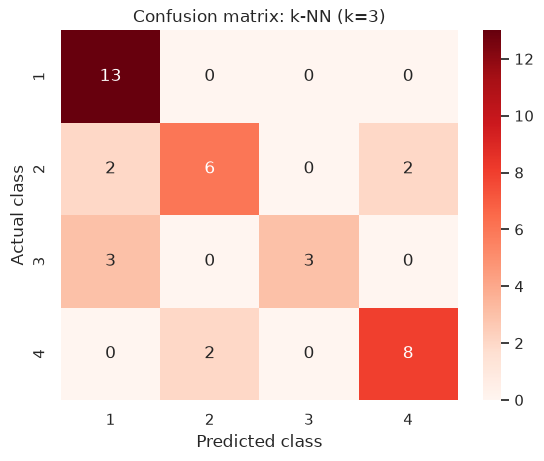

In [33]:
# Confusion matrix for the chosen k
cf_best = confusion_matrix(y_test, y_pred_best, labels=labels)

sns.heatmap(cf_best, annot=True, fmt='d', cmap='Reds',
            xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted class')
plt.ylabel('Actual class')
plt.title(f'Confusion matrix: k-NN (k={best_k})')
plt.show()

### Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)          # unscaled data

y_pred_rf = rf.predict(X_test)
acc_rf = accuracy_score(y_test, y_pred_rf)
print("Random Forest test accuracy:", round(acc_rf, 3))
print()
print(classification_report(y_test, y_pred_rf))

Random Forest test accuracy: 0.872

              precision    recall  f1-score   support

           1       0.87      1.00      0.93        13
           2       1.00      0.70      0.82        10
           3       1.00      0.67      0.80         6
           4       0.77      1.00      0.87        10

    accuracy                           0.87        39
   macro avg       0.91      0.84      0.86        39
weighted avg       0.90      0.87      0.87        39



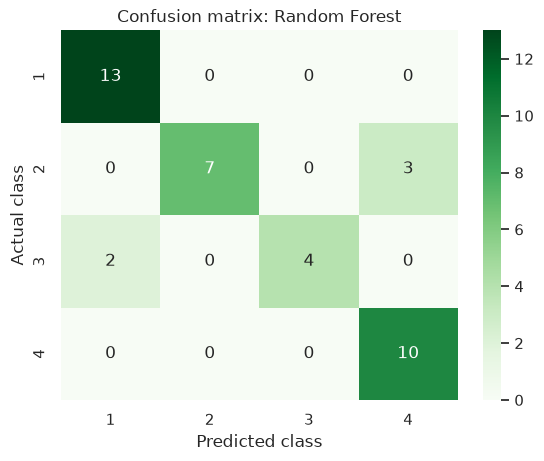

In [30]:
cf_rf = confusion_matrix(y_test, y_pred_rf, labels=labels)

sns.heatmap(cf_rf, annot=True, fmt='d', cmap='Greens',
            xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted class')
plt.ylabel('Actual class')
plt.title('Confusion matrix: Random Forest')
plt.show()

#### Which variables matter most?

  feature  importance
3    size    0.646898
1       G    0.122359
2       B    0.119574
0       R    0.111169


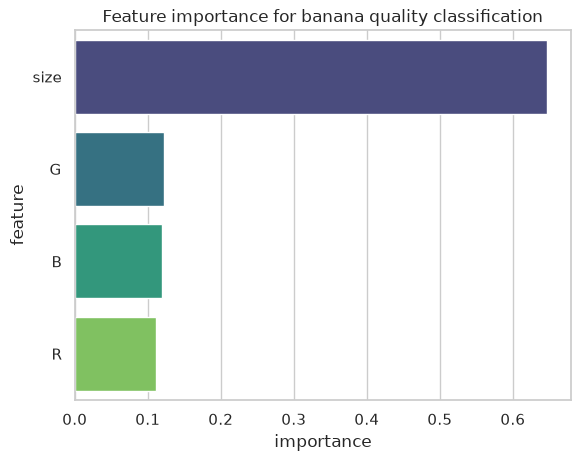

In [31]:
feature_importances = pd.DataFrame({'feature': X.columns, 'importance': rf.feature_importances_})
feature_importances = feature_importances.sort_values(by='importance', ascending=False)
print(feature_importances)

sns.barplot(x='importance', y='feature', hue='feature', data=feature_importances,
            palette='viridis', legend=False)
plt.title('Feature importance for banana quality classification')
plt.show()

#### Comparison of the models

In [32]:
results = pd.DataFrame({
    'Model': ['k-NN (k=5)', f'k-NN (k={best_k})', 'Random Forest'],
    'Test accuracy': [acc_knn5, acc_knn_best, acc_rf]
})
results['Test accuracy'] = results['Test accuracy'].round(3)
results

,Model,Test accuracy
0,k-NN (k=5),0.744
1,k-NN (k=3),0.769
2,Random Forest,0.872


### Predicting a new banana

The activity asks us to predict an example that is **not** in the training or test data. We invent a new banana tier with these measurements (color values and finger length typical of the dataset):

- R = 85, G = 108, B = 48
- finger length = 150 mm

For $k$-NN we must apply the **same scaler** used in training. For Random Forest we use the raw values.

In [33]:
# A new banana tier (not in the dataset)
new_banana = pd.DataFrame({'R': [85], 'G': [108], 'B': [48], 'size': [150]})

# k-NN: scale first, then predict
pred_knn = knn_best.predict(scaler.transform(new_banana))[0]
proba_knn = knn_best.predict_proba(scaler.transform(new_banana))[0]

# Random Forest: predict directly
pred_rf = rf.predict(new_banana)[0]
proba_rf = rf.predict_proba(new_banana)[0]

print(f"k-NN (k={best_k}) predicts class:", pred_knn)
print("   probabilities by class:", {int(c): round(float(p), 2) for c, p in zip(knn_best.classes_, proba_knn)})
print("Random Forest predicts class:", pred_rf)
print("   probabilities by class:", {int(c): round(float(p), 2) for c, p in zip(rf.classes_, proba_rf)})

k-NN (k=3) predicts class: 1
   probabilities by class: {1: 1.0, 2: 0.0, 3: 0.0, 4: 0.0}
Random Forest predicts class: 1
   probabilities by class: {1: 0.98, 2: 0.01, 3: 0.01, 4: 0.0}


### Saving the trained model

In [34]:
import joblib

# Save the scaler and the model together so they can be reused later
joblib.dump({'scaler': scaler, 'model': knn_best}, 'knn_banana_model.pkl')

# Load them again and check that they give the same prediction
saved = joblib.load('knn_banana_model.pkl')
print(saved['model'].predict(saved['scaler'].transform(new_banana))[0])

1


## **Conclusions**

In this notebook we explored a real dataset of banana tiers, prepared it for machine learning and trained two classifiers to predict the commercial quality class (1 to 4) from color (R, G, B) and finger length.

**What we did**
1. We found that the 1,164 rows were not 1,164 bananas: every tier appears 6 times (one photo per side). Averaging the color over the 6 views gave **one row per tier (194 rows)** and avoided data leakage between the training and test sets.
2. We scaled the variables before using $k$-NN, because it is based on distances and `size` (in millimeters) would otherwise dominate the color values.
3. We chose $k$ with repeated cross-validation on the training data, not on the test set.

**Results (test set of 39 tiers)**

| Model | Accuracy |
|---|---|
| $k$-NN, $k=5$ | 74.4% |
| $k$-NN, $k=3$ (chosen with cross-validation) | 76.9% |
| Random Forest | 87.2% |

- **Random Forest performed better** than $k$-NN in this run. A possible reason is that it can use the variables in different ways for different classes, and it is not affected by the strong correlation between R, G and B. 
- **Finger length (`size`) is by far the most important variable** (about 65% of the importance), while R, G and B contribute about 11-12% each. This agrees with the boxplot: size separates the classes much better than color does.
- The classes with fewer tiers (especially class 3, with 30 tiers and only 6 in the test set) have lower recall, so the models miss some of them.

**Limitations**
- The test set is small: **one tier changes the accuracy by about 2.6%**, so the difference between $k=3$ and $k=5$ is not meaningful, and even the gap between $k$-NN and Random Forest should be taken with some caution. A different random split could give slightly different numbers.
- The classes are somewhat imbalanced and overlap in color, so a perfect classifier should not be expected.
- The quality classes were assigned by a human expert, so part of the "error" may come from the subjectivity of the labels.

**Possible improvements**
- Use more tiers, or cross-validation for the final evaluation instead of a single split.
- Add new features, such as the size of more than one finger, color in another space (for example LAB) or the standard deviation of the color over the 6 views (here we only kept the mean).
- Tune the Random Forest (number and depth of trees) and compare it with other models.